In [ ]:
import sys
import os

# Проверяем, запущен ли ноутбук в среде Google Colab
if "google.colab" in sys.modules:
    !pip install uv -q
    !wget https://raw.githubusercontent.com/alex-hse-repository/time-series-cu-2026/refs/heads/main/week_10/pyproject.toml -q
    !uv pip install -r pyproject.toml --system -q
    os.kill(os.getpid(), 9)  # force runtime restart


# 5. Кейс Walmart Recruiting

**Сквозной вопрос блока:** чек-лист реального проекта — бейзлайн → честная валидация → признаки → отбор → масштаб.

В этом ноутбуке:
- задача Kaggle Walmart Recruiting: недельные продажи Store × Dept, горизонт 39 недель, метрика WMAE;
- подготовка: слияние таблиц, преобразование таргета, только сегменты из теста, заполнение пропусков;
- локальная валидация на отложенных 39 неделях и бейзлайн «та же неделя прошлого года»;
- признаки без лагов: календарь, гармоники, взаимодействие сегмент × неделя, скользящие и сезонные статистики;
- глобальный CatBoost с потерями MAE и RMSE и их ансамбль;
- поправка на сдвиг Рождества — проверяем на валидации, а не на лидерборде;
- эпилог: переобучение на всех данных и сабмит.

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from catboost import CatBoostRegressor

plt.rcParams['figure.figsize'] = (12, 4)

H = 39   # горизонт, недель


def wmae(y, y_hat, is_holiday):
    """Weighted MAE: праздничные недели с весом 5."""
    w = np.where(is_holiday, 5, 1)
    return np.sum(w * np.abs(y - y_hat)) / np.sum(w)

## 0. Задача

45 магазинов Walmart, в каждом десятки отделов. Нужно спрогнозировать недельные продажи каждого отдела
каждого магазина (сегмент Store × Dept) на 39 недель вперёд. Метрика:

$$\mathrm{WMAE} = \frac{1}{\sum w_i}\sum_i w_i\,|y_i - \hat y_i|, \quad w_i = 5 \text{ для праздничных недель, иначе } 1.$$

Праздничные недели — Super Bowl, День труда, День благодарения и неделя после Рождества: ошибка в них
стоит в 5 раз дороже.

## 1. Подготовка данных

In [2]:
train = pd.read_csv('https://raw.githubusercontent.com/alex-hse-repository/time-series-cu-2026/refs/heads/main/week_10/data/walmart_train.csv', parse_dates=['Date'])
test = pd.read_csv('https://raw.githubusercontent.com/alex-hse-repository/time-series-cu-2026/refs/heads/main/week_10/data/walmart_test.csv', parse_dates=['Date'])
stores = pd.read_csv('https://raw.githubusercontent.com/alex-hse-repository/time-series-cu-2026/refs/heads/main/week_10/data/walmart_stores.csv')
weather = pd.read_csv('https://raw.githubusercontent.com/alex-hse-repository/time-series-cu-2026/refs/heads/main/week_10/data/walmart_features.csv', parse_dates=['Date'], usecols=['Store', 'Date', 'Temperature'])


def prepare(df):
    df = (df.merge(stores, on='Store', how='left')
            .merge(weather, on=['Store', 'Date'], how='left'))
    df['IsHoliday'] = df['IsHoliday'].astype(int)
    df['segment'] = df['Store'].astype(str) + '_' + df['Dept'].astype(str)
    return df


train, test = prepare(train), prepare(test)
print(f'train: {train["Date"].min().date()} — {train["Date"].max().date()}, {train["Date"].nunique()} недель, '
      f'{train["segment"].nunique()} сегментов')
print(f'test:  {test["Date"].min().date()} — {test["Date"].max().date()}, {test["Date"].nunique()} недель, '
      f'{test["segment"].nunique()} сегментов')
train.head()

train: 2010-02-05 — 2012-10-26, 143 недель, 3331 сегментов
test:  2012-11-02 — 2013-07-26, 39 недель, 3169 сегментов


,Store,Dept,Date,Weekly_Sales,IsHoliday,Type,Size,Temperature,segment
0,1,1,2010-02-05,24924.50,0,A,151315,42.31,1_1
1,1,1,2010-02-12,46039.49,1,A,151315,38.51,1_1
2,1,1,2010-02-19,41595.55,0,A,151315,39.93,1_1
3,1,1,2010-02-26,19403.54,0,A,151315,46.63,1_1
4,1,1,2010-03-05,21827.90,0,A,151315,46.50,1_1


### Сегменты

Обучаемся только на сегментах, которые есть в тесте: остальные модели не нужны. Несколько сегментов есть
только в тесте — истории у них нет, их прогноз модель построит по магазину, отделу и календарю.

In [3]:
test_segments = set(test['segment'])
print('сегментов только в train:', len(set(train['segment']) - test_segments))
print('сегментов только в test: ', len(test_segments - set(train['segment'])))

train = train[train['segment'].isin(test_segments)].reset_index(drop=True)

сегментов только в train: 173
сегментов только в test:  11


### Преобразование таргета

Продажи разных отделов отличаются на порядки, а распределение с тяжёлым правым хвостом. Берём корень четвёртой
степени $|y|^{1/4}$ — грубый аналог Бокса–Кокса с $\lambda = 0.25$. Модуль теряет знак: отрицательные
продажи (возвраты) после обратного преобразования станут положительными. Их доля мала — ниже проверим.

доля отрицательных продаж: 0.28%


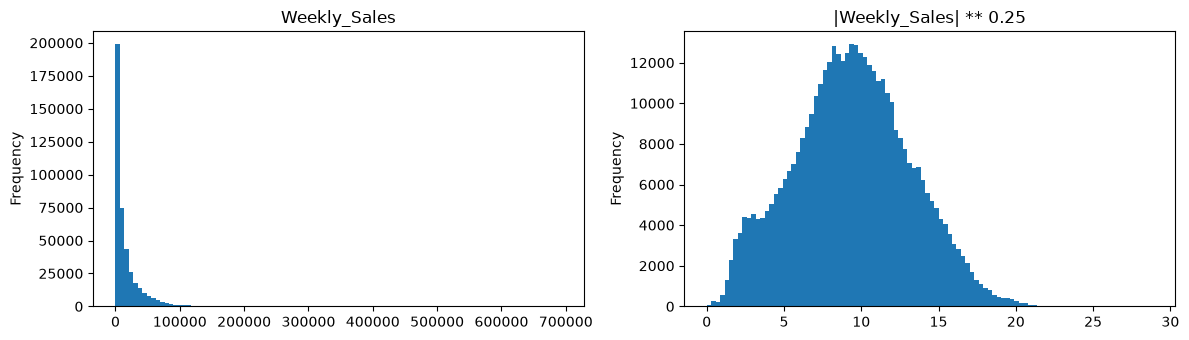

In [4]:
print(f'доля отрицательных продаж: {(train["Weekly_Sales"] < 0).mean():.2%}')
train['y'] = train['Weekly_Sales'].abs() ** 0.25

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
train['Weekly_Sales'].clip(lower=0).plot(kind='hist', bins=100, ax=axes[0], title='Weekly_Sales')
train['y'].plot(kind='hist', bins=100, ax=axes[1], title='|Weekly_Sales| ** 0.25')
plt.tight_layout()
plt.show()

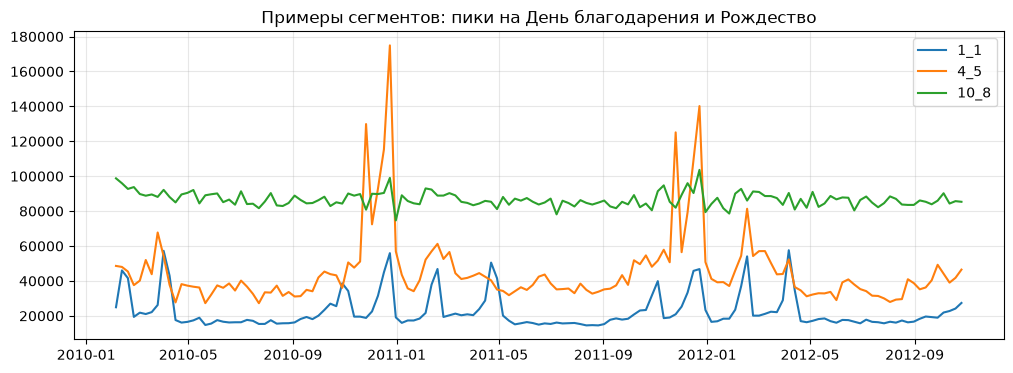

In [5]:
examples = ['1_1', '4_5', '10_8']
for seg in examples:
    s = train[train['segment'] == seg]
    plt.plot(s['Date'], s['Weekly_Sales'], label=seg)
plt.title('Примеры сегментов: пики на День благодарения и Рождество')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Пропуски

Ряды разной длины: какие-то отделы открывались позже, в каких-то недели пропущены. Для скользящих статистик
нужна полная сетка «неделя × сегмент» — заполняем её линейной интерполяцией в обе стороны.
Обучаемся и оцениваем качество только на настоящих наблюдениях: интерполяция нужна лишь для признаков.

In [6]:
weeks_observed = train.groupby('segment')['Date'].nunique()
print(f'сегментов с полной историей ({train["Date"].nunique()} недель): {(weeks_observed == train["Date"].nunique()).mean():.0%}, '
      f'минимум недель: {weeks_observed.min()}')

сегментов с полной историей (143 недель): 84%, минимум недель: 1


## 2. Валидация и бейзлайн

Без локальной валидации остаётся только лидерборд Kaggle — и любой подбор по нему превращает лидерборд
в обучающую выборку.

**Какое окно отложить.** Последние 39 недель train (февраль — октябрь 2012) не содержат Рождества, а тест
(ноябрь 2012 — июль 2013) начинается с Дня благодарения и Рождества. Поэтому откладываем окно той же сезонности
годом раньше: 39 недель с 2011-11-04 по 2012-07-27. Обучаемся только на том, что было до него.

In [7]:
VAL_START = pd.Timestamp('2011-11-04')
VAL_END = VAL_START + pd.Timedelta(weeks=H - 1)
TEST_START = test['Date'].min()

val_mask = train['Date'].between(VAL_START, VAL_END)
print(f'обучение: {train.loc[train["Date"] < VAL_START, "Date"].nunique()} недель, '
      f'валидация: {train.loc[val_mask, "Date"].nunique()} недель ({VAL_START.date()} — {VAL_END.date()})')

обучение: 91 недель, валидация: 39 недель (2011-11-04 — 2012-07-27)


**Бейзлайн — та же неделя прошлого года** (52 недели назад). Для всего горизонта эта неделя уже известна.

In [8]:
ALL_DATES = pd.DatetimeIndex(sorted(set(train['Date']) | set(test['Date'])))   # сетка недель train + test

sales_wide = train.pivot(index='Date', columns='segment', values='Weekly_Sales').reindex(ALL_DATES)
last_year = sales_wide.shift(52).stack().rename('baseline')

val = train[val_mask].join(last_year, on=['Date', 'segment'])
val['baseline'] = val['baseline'].fillna(0)

scores = {'Та же неделя прошлого года': wmae(val['Weekly_Sales'], val['baseline'], val['IsHoliday'])}
pd.Series(scores, name='WMAE на валидации').round(1)

Та же неделя прошлого года    2017.0
Name: WMAE на валидации, dtype: float64

## 3. Признаки

**Лагов нет:** горизонт 39 недель, для конца горизонта лаги ≥ 39 — почти год назад, полезнее явно задать сезонность.

- **календарь и гармоники** недели года;
- **сегмент × неделя года** (`segment_week`) — категориальный признак «у этого отдела этого магазина в эту неделю».
  Деревья в принципе находят взаимодействия сами, но Store = 12 & Dept = 34 & week = 50 — три сплита ради одной
  комбинации из десятков тысяч. Явный признак даёт это сразу; CatBoost кодирует такую категорию
  целевыми статистиками (ordered target statistics) без one-hot;
- **скользящие средние и медианы** с окном ≥ H по ряду, где будущее закрыто NaN, — уровень сегмента;
- **сезонные статистики**: та же неделя год назад и медиана той же недели за прошлые годы.

Все статистики считаем в широкой таблице «неделя × сегмент»: окно и сдвиг применяются сразу ко всем
3000 рядам, без цикла по сегментам и без `groupby`.

In [9]:
ROLL_WINDOWS = [39, 52, 78]


def history_wide(cutoff):
    """Таргет в широком формате: интерполяция только по истории до cutoff, будущее — NaN."""
    hist = train[train['Date'] < cutoff].pivot(index='Date', columns='segment', values='y')
    hist = hist.interpolate(method='linear', limit_direction='both')
    return hist.reindex(ALL_DATES)


def series_features(cutoff):
    """Скользящие и сезонные статистики для всех (неделя, сегмент) при истории до cutoff."""
    wide = history_wide(cutoff)
    shifted = wide.shift(1)
    stats = {}
    for w in ROLL_WINDOWS:
        stats[f'roll_mean_{w}'] = shifted.rolling(w, min_periods=1).mean()
        stats[f'roll_median_{w}'] = shifted.rolling(w, min_periods=1).median()
    stats['same_week_last_year'] = wide.shift(52)
    stats['same_week_median'] = pd.concat([wide.shift(52), wide.shift(104)]).groupby(level=0).median()
    return pd.concat({name: df.stack(future_stack=True) for name, df in stats.items()}, axis=1)


def calendar_features(df):
    week = df['Date'].dt.isocalendar().week.astype(int)
    return df.assign(
        week=week,
        month=df['Date'].dt.month,
        week_sin=np.sin(2 * np.pi * week / 52.18),
        week_cos=np.cos(2 * np.pi * week / 52.18),
        segment_week=df['segment'] + '_' + week.astype(str),
    )


def make_dataset(rows, cutoff):
    return calendar_features(rows).join(series_features(cutoff), on=['Date', 'segment'])


CAT_FEATURES = ['Store', 'Dept', 'Type', 'segment', 'segment_week']
NUM_FEATURES = ['Size', 'Temperature', 'IsHoliday', 'week', 'month', 'week_sin', 'week_cos',
                *[f'roll_{s}_{w}' for w in ROLL_WINDOWS for s in ('mean', 'median')],
                'same_week_last_year', 'same_week_median']
FEATURES = CAT_FEATURES + NUM_FEATURES

**Где здесь защита от утечки.** `history_wide(cutoff)` берёт только факт до `cutoff` — и интерполирует тоже
только его: интерполяция по всему ряду заполнила бы пропуски перед окном с помощью значений из окна.
Сезонные признаки на горизонте целиком известны (52 ≥ 39), а скользящие окна по мере удаления от начала
горизонта опираются на всё меньшую часть окна — поэтому окна не короче H.

In [10]:
example = make_dataset(train[(train['segment'] == '1_1') & (train['Date'] >= VAL_START - pd.Timedelta(weeks=2))].head(6), VAL_START)
example[['Date', 'segment', 'segment_week', 'Weekly_Sales', 'roll_mean_39', 'same_week_last_year', 'same_week_median']]

,Date,segment,segment_week,Weekly_Sales,roll_mean_39,same_week_last_year,same_week_median
89,2011-10-21,1_1,1_1_42,23351.80,11.867201,12.642069,12.642069
90,2011-10-28,1_1,1_1_43,31579.90,11.889926,14.020448,14.020448
91,2011-11-04,1_1,1_1_44,39886.06,11.932856,13.602849,13.602849
92,2011-11-11,1_1,1_1_45,18689.54,11.927607,11.824514,11.824514
93,2011-11-18,1_1,1_1_46,19050.66,11.872906,11.825036,11.825036
94,2011-11-25,1_1,1_1_47,20911.25,11.794045,11.712688,11.712688


## 4. Модель: глобальный CatBoost

Одна модель на все сегменты. Две функции потерь на преобразованном таргете:
- **MAE** — ближе к метрике (WMAE — взвешенный MAE);
- **RMSE** — тянется к среднему, ошибается иначе; в ансамбле ошибки двух моделей частично компенсируются.

Праздничным неделям даём вес 5 — как в метрике. После прогноза — обратное преобразование $\hat y^4$
и обрезка отрицательных.

### 4.1. Прямой прогноз таргета

In [11]:
CB_PARAMS = dict(iterations=1000, learning_rate=0.1, depth=8, random_seed=42, verbose=0,
                 cat_features=CAT_FEATURES)


def fit_predict(train_rows, predict_rows, cutoff, loss, residual=False):
    """Обучает CatBoost на истории до cutoff и прогнозирует predict_rows в исходной шкале.

    residual=True — модель учит отклонение от той же недели прошлого года (в шкале |y|^(1/4)).
    """
    data = make_dataset(pd.concat([train_rows, predict_rows]), cutoff)
    fit_part, pred_part = data.iloc[:len(train_rows)], data.iloc[len(train_rows):]
    if residual:
        fit_part = fit_part[fit_part['same_week_last_year'].notna()]
        target = fit_part['y'] - fit_part['same_week_last_year']
        # нет прошлого года (новый сегмент) — опираемся на средний уровень, а если нет и его — на ноль
        anchor = pred_part['same_week_last_year'].fillna(pred_part['roll_mean_52']).fillna(0).to_numpy()
    else:
        target, anchor = fit_part['y'], 0
    model = CatBoostRegressor(loss_function=loss, **CB_PARAMS)
    model.fit(fit_part[FEATURES], target, sample_weight=np.where(fit_part['IsHoliday'], 5, 1))
    return model, np.clip(anchor + model.predict(pred_part[FEATURES]), 0, None) ** 4


def add_models(prefix, residual):
    models = {}
    for loss in ['MAE', 'RMSE']:
        models[loss], val[f'{prefix} {loss}'] = fit_predict(train_rows, val, VAL_START, loss, residual)
    val[f'{prefix} ансамбль'] = (val[f'{prefix} MAE'] + val[f'{prefix} RMSE']) / 2
    for name in [f'{prefix} MAE', f'{prefix} RMSE', f'{prefix} ансамбль']:
        scores[name] = wmae(val['Weekly_Sales'], val[name], val['IsHoliday'])
    return models


train_rows = train[train['Date'] < VAL_START]
add_models('Прямой', residual=False)
pd.Series(scores, name='WMAE на валидации').round(1)

Та же неделя прошлого года    2017.0
Прямой MAE                    2579.9
Прямой RMSE                   2287.9
Прямой ансамбль               2321.7
Name: WMAE на валидации, dtype: float64

**Прямой прогноз проигрывает бейзлайну** (ансамбль 2322, MAE 2580 против 2017 у «той же недели год назад»).
Признак `same_week_last_year` у модели есть, но деревья кусочно-постоянны. Чтобы воспроизвести тождество
«как год назад» для 3000 рядов разного масштаба, нужны тысячи сплитов, и каждая ступенька — ошибка.
Обратное преобразование $\hat y^4$ раздувает эти ошибки на крупных сегментах, а они и определяют WMAE.

### 4.2. Бустинг поверх бейзлайна

Пусть модель учит не сами продажи, а **поправку к бейзлайну**: $r = y^{1/4} - y^{1/4}_{\text{год назад}}$,
прогноз $\hat y = (y^{1/4}_{\text{год назад}} + \hat r)^4$. Тождество «как год назад» модели больше не нужно
собирать из сплитов — оно встроено, а деревья описывают только отличия: тренд сегмента, сдвиг праздников,
погоду. Учимся на строках, где прошлый год известен.

In [12]:
residual_models = add_models('Поверх бейзлайна', residual=True)
pd.Series(scores, name='WMAE на валидации').round(1)

Та же неделя прошлого года    2017.0
Прямой MAE                    2579.9
Прямой RMSE                   2287.9
Прямой ансамбль               2321.7
Поверх бейзлайна MAE          2008.2
Поверх бейзлайна RMSE         2004.8
Поверх бейзлайна ансамбль     1991.4
Name: WMAE на валидации, dtype: float64

Веса ансамбля — поровну. Подбирать их по валидации можно, но тогда для честной оценки нужна ещё одна
отложенная выборка; подбирать по лидерборду — тем более.

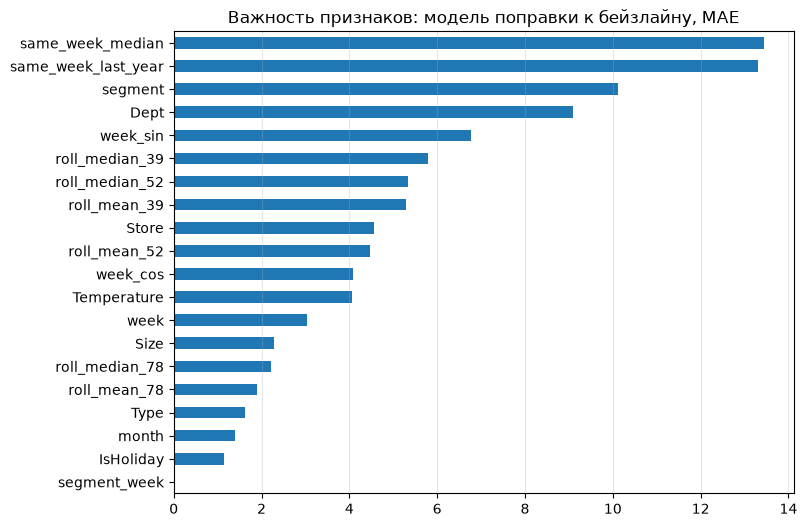

In [13]:
importance = pd.Series(residual_models['MAE'].get_feature_importance(), index=FEATURES).sort_values()
importance.plot(kind='barh', figsize=(8, 6), title='Важность признаков: модель поправки к бейзлайну, MAE')
plt.grid(alpha=0.3, axis='x')
plt.show()

- Поправка к бейзлайну выигрывает у него, но немного: ансамбль 1991 против 2017 (−1.3%).
  Ансамбль лучше каждой из моделей по отдельности.
- Главные признаки поправки — `same_week_median` и `same_week_last_year`: насколько сильно поправлять, зависит от
  уровня прошлого года (после аномально высокой недели продажи обычно ниже). Дальше идут `segment` и `Dept` —
  у каждого сегмента свой тренд.
- `segment_week` здесь бесполезен. Модель поправки учится только на строках с известным прошлым годом, это 39 недель,
  и каждая комбинация «сегмент × неделя» встречается в обучении один раз: усреднять нечего. Явное взаимодействие
  работает, когда комбинация повторяется, то есть при нескольких годах истории.

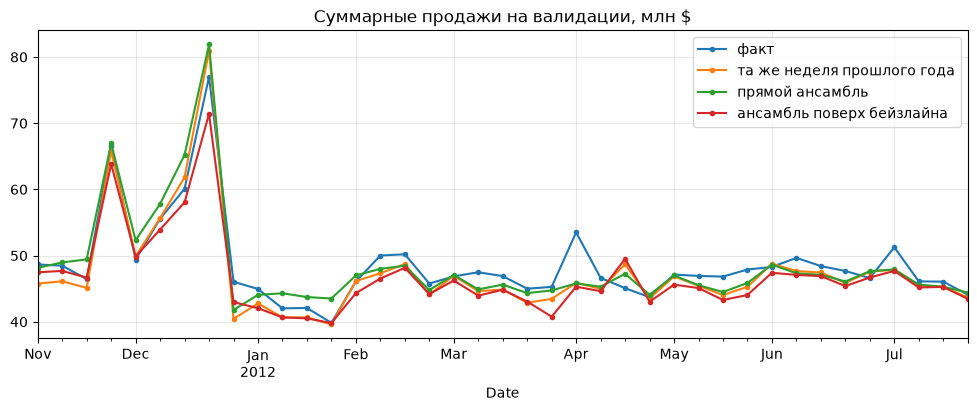

In [14]:
weekly = val.groupby('Date')[['Weekly_Sales', 'baseline', 'Прямой ансамбль', 'Поверх бейзлайна ансамбль']].sum() / 1e6
weekly.columns = ['факт', 'та же неделя прошлого года', 'прямой ансамбль', 'ансамбль поверх бейзлайна']
weekly.plot(title='Суммарные продажи на валидации, млн $', marker='.')
plt.grid(alpha=0.3)
plt.show()

## 5. Поправка на сдвиг Рождества

Даты в данных — пятницы, неделя заканчивается в пятницу. Сколько самых «горячих» предрождественских дней
(18–24 декабря) попадает в 51-ю неделю, зависит от года:

| год | 51-я неделя | дней из 18–24 декабря в ней |
|---|---|---|
| 2010 | 18–24 декабря | 7 |
| 2011 | 17–23 декабря | 6 |
| 2012 | 15–21 декабря | 4 |

И бейзлайн, и модель опираются на прошлые годы, где пик почти целиком в 51-й неделе, и переносят его туда же.
А в 2011 и особенно 2012 часть пика уходит в 52-ю неделю. Ошибка по 52-й неделе стоит в 5 раз дороже
(это праздничная неделя).

Две поправки:
- **правило с порогами:** если прогноз 51-й недели больше 1.5 × прогноза 52-й — уменьшить его на 15%;
  если прогноз 52-й, даже увеличенный в 1.65 раза, меньше прогноза 51-й — увеличить его в 1.5 раза;
- **сдвиг на разницу в днях:** перенести долю $s = \Delta/7$ прогноза между неделями 51 и 52, где $\Delta$ —
  на сколько дней меньше пика попало в 51-ю неделю, чем в обучающих годах. Для валидации (обучение на 2010):
  $s = 1/7$.

In [15]:
def christmas_wide(df, col):
    week = df['Date'].dt.isocalendar().week
    return df.assign(week=week).query('week in [51, 52]').pivot(index='segment', columns='week', values=col)


def rule_correction(df, col):
    p = christmas_wide(df, col)
    p51 = np.where(p[51] > 1.5 * p[52], 0.85 * p[51], p[51])
    p52 = np.where(1.65 * p[52] < p[51], 1.5 * p[52], p[52])
    return apply_christmas(df, col, pd.DataFrame({51: p51, 52: p52}, index=p.index))


def shift_correction(df, col, s):
    p = christmas_wide(df, col)
    corrected = pd.DataFrame({51: (1 - s) * p[51] + s * p[52], 52: (1 - s) * p[52] + s * p[51]}, index=p.index)
    return apply_christmas(df, col, corrected)


def apply_christmas(df, col, corrected):
    week = df['Date'].dt.isocalendar().week
    out = df[col].copy()
    for w in (51, 52):
        mask = week == w
        out[mask] = df.loc[mask, 'segment'].map(corrected[w]).fillna(df.loc[mask, col]).to_numpy()
    return out


for base in ['baseline', 'Поверх бейзлайна ансамбль']:
    val[f'{base} + правило'] = rule_correction(val, base)
    val[f'{base} + сдвиг 1/7'] = shift_correction(val, base, s=1 / 7)

xmas = val['Date'].dt.isocalendar().week.isin([51, 52])
correction_table = pd.DataFrame({
    name: {'WMAE (вся валидация)': wmae(val['Weekly_Sales'], val[name], val['IsHoliday']),
           'WMAE (недели 51–52)': wmae(val.loc[xmas, 'Weekly_Sales'], val.loc[xmas, name], val.loc[xmas, 'IsHoliday'])}
    for base in ['baseline', 'Поверх бейзлайна ансамбль']
    for name in [base, f'{base} + правило', f'{base} + сдвиг 1/7']
}).T.rename(index=lambda s: s.replace('baseline', 'Та же неделя прошлого года'))
correction_table.round(1)

,WMAE (вся валидация),WMAE (недели 51–52)
Та же неделя прошлого года,2017.0,2820.4
Та же неделя прошлого года + правило,2018.3,2831.9
Та же неделя прошлого года + сдвиг 1/7,1922.9,2029.0
Поверх бейзлайна ансамбль,1991.4,2628.5
Поверх бейзлайна ансамбль + правило,2023.2,2896.1
Поверх бейзлайна ансамбль + сдвиг 1/7,1968.3,2433.9


- **Правило с порогами вредит** и бейзлайну (2017 → 2018), и модели (1991 → 2023); на неделях 51–52 — заметно.
  Пороги 1.5 / 1.65 / 0.85 подобраны по лидерборду под другой год и на нашей валидации не работают.
- **Сдвиг на число дней помогает** обоим: на неделях 51–52 ошибка бейзлайна падает с 2820 до 2029 (−28%),
  модели — с 2629 до 2434. В целом по валидации: бейзлайн 2017 → 1923, модель 1991 → 1968.
- Поправка с одним параметром, выведенным из календаря, дала больше, чем вся модель поверх бейзлайна.

### Итог валидации

In [16]:
for base in ['baseline', 'Поверх бейзлайна ансамбль']:
    name = f'{base} + сдвиг 1/7'
    scores[name.replace('baseline', 'Та же неделя прошлого года')] = wmae(val['Weekly_Sales'], val[name], val['IsHoliday'])
pd.Series(scores, name='WMAE на валидации').sort_values().round(1).to_frame()

,WMAE на валидации
Та же неделя прошлого года + сдвиг 1/7,1922.9
Поверх бейзлайна ансамбль + сдвиг 1/7,1968.3
Поверх бейзлайна ансамбль,1991.4
Поверх бейзлайна RMSE,2004.8
Поверх бейзлайна MAE,2008.2
Та же неделя прошлого года,2017.0
Прямой RMSE,2287.9
Прямой ансамбль,2321.7
Прямой MAE,2579.9


**Лучший на валидации — бейзлайн со сдвигом Рождества (1923)**, бустинг поверх бейзлайна со сдвигом — 1968.

- Без бейзлайна мы бы этого не узнали: прямой бустинг (2322) выглядел бы нормальным результатом.
- На этой валидации модель видит мало: прошлый год известен лишь для 39 обучающих недель, и среди них нет Рождества.
  При переобучении на всех данных таких недель 91, включая Рождество 2011, и модель может стать полезнее.
  Но проверить это локально уже нельзя — это и есть цена честной валидации.
- Решение по валидации: основной сабмит — бейзлайн со сдвигом, бустинг — второй, для сравнения на лидерборде.

## 6. Эпилог: переобучение и сабмит

Схема та же, что на валидации, но история — весь train, прогноз — на тест Kaggle. Сдвиг Рождества для 2012:
в обучении 2010 и 2011 годы (в среднем 6.5 дня пика в 51-й неделе), в 2012 — 4 дня, $s = 2.5/7$.
Сохраняем два сабмита: бустинг поверх бейзлайна и сам бейзлайн, оба с поправкой.

In [17]:
final = test.copy()
for loss in ['MAE', 'RMSE']:
    _, final[f'CatBoost {loss}'] = fit_predict(train, final, TEST_START, loss, residual=True)
final['ensemble'] = (final['CatBoost MAE'] + final['CatBoost RMSE']) / 2
final['baseline'] = final.join(last_year, on=['Date', 'segment'])['baseline'].fillna(0)


def save_submission(col, path):
    pd.DataFrame({
        'Id': final['Store'].astype(str) + '_' + final['Dept'].astype(str) + '_' + final['Date'].dt.strftime('%Y-%m-%d'),
        'Weekly_Sales': shift_correction(final, col, s=2.5 / 7),
    }).to_csv(path, index=False)


save_submission('ensemble', '../data/walmart_submission_catboost.csv')
save_submission('baseline', '../data/walmart_submission_last_year.csv')

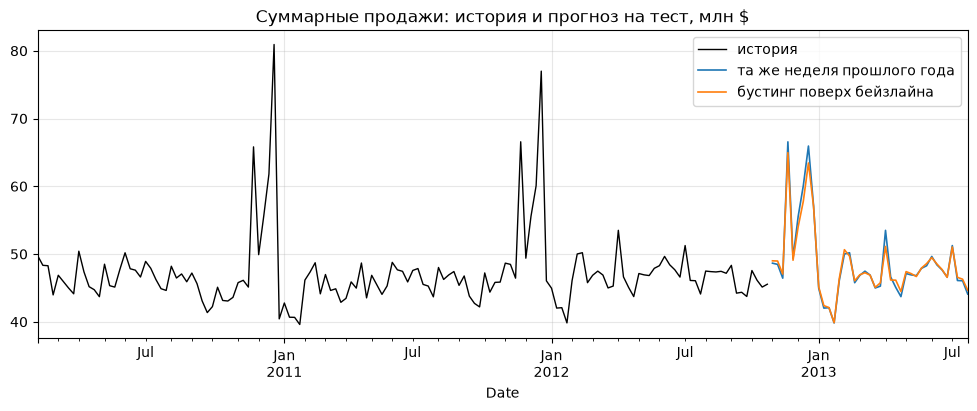

In [18]:
hist_total = train.groupby('Date')['Weekly_Sales'].sum() / 1e6
hist_total.plot(label='история', color='black', lw=1)
for col, label in [('baseline', 'та же неделя прошлого года'), ('ensemble', 'бустинг поверх бейзлайна')]:
    (shift_correction(final, col, s=2.5 / 7).groupby(final['Date']).sum() / 1e6).plot(label=label, lw=1.2)
plt.title('Суммарные продажи: история и прогноз на тест, млн $')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Файлы можно отправить на Kaggle (соревнование закрыто, но late submission принимается).
Для ориентира: лучшее решение соревнования — около 2300 WMAE на private. Подход «бустинг + сезонные признаки +
поправка на праздники» с весами ансамбля и поправкой, подобранными по лидерборду, получает около 2350.
Такой скор нельзя честно сравнивать с нашим: у нас все решения приняты на локальной валидации,
а лидерборд — только финальная проверка.

## Итог

| Шаг чек-листа | Что сделали | Чему научились |
|---|---|---|
| Подготовка | слияние таблиц, $\lvert y\rvert^{1/4}$, сегменты из теста, интерполяция только для признаков | преобразование таргета теряет знак; метрика — по настоящим наблюдениям |
| Валидация | 39 недель той же сезонности годом раньше, WMAE, бейзлайн «год назад» | окно валидации должно содержать то, что важно в тесте (праздники) |
| Признаки | календарь, сегмент × неделя, скользящие (окно ≥ H) и сезонные статистики | на длинном горизонте сезонность важнее лагов; явное взаимодействие полезно, только если комбинации повторяются |
| Модель | глобальный CatBoost, MAE и RMSE, вес 5 праздникам, ансамбль поровну | прямой прогноз проиграл бейзлайну; бустинг поверх бейзлайна (учим поправку) — чуть лучше него |
| Поправки | правило с порогами vs сдвиг Рождества по числу дней | порог, подобранный по лидерборду, вредит; поправка из календаря дала больше модели |
| Масштаб | широкая таблица: окна сразу по всем рядам | `numba` и циклы по сегментам не нужны |

Главный урок блока: **бейзлайн — не формальность**. Здесь он сначала обыграл бустинг, а потом стал его основой.